# 1 Missing and Erroneous Values

In the following notebook we go through all the columns that have missing or wrong data and decide what to do with each one. We load the output from notebook 00 and save a clean version at the end.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

# Consistent visual style
sns.set_theme(style="whitegrid", palette="colorblind", font_scale=1.1)
plt.rcParams.update({"figure.dpi": 120, "axes.titlesize": 13, "axes.labelsize": 11})

PERIOD_MAP = {"201803": "Q1 2018", "201806": "Q2 2018", "201809": "Q3 2018", "201812": "Q4 2018"}

df = pd.read_parquet("../data/processed/listings_00.parquet")

print(f"Loaded: {df.shape[0]:,} rows × {df.shape[1]} columns")

Loaded: 94,815 rows × 41 columns


## Missing values overview

,Missing,% of total
CONSTRUCTIONYEAR,55873,58.93
FLATLOCATIONID,6387,6.74
FLOORCLEAN,3846,4.06
CADASTRALQUALITYID,1,0.00


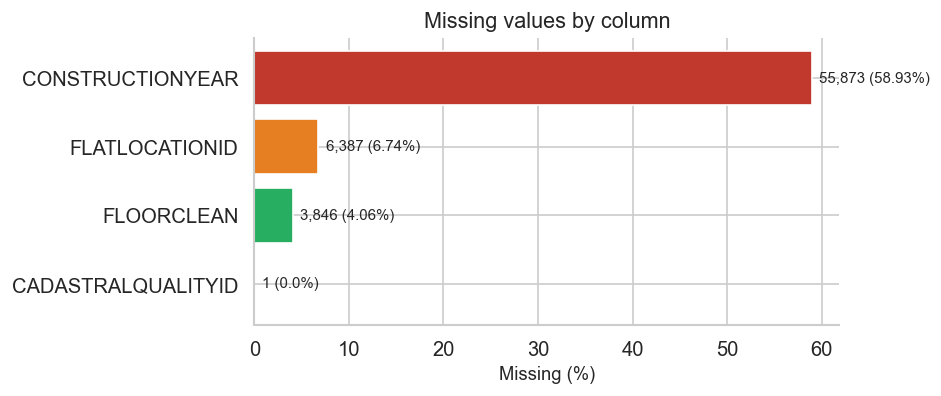

In [2]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)

missing_df = pd.DataFrame({"Missing": missing, "% of total": missing_pct})
display(missing_df)

# Bar chart of missing percentages
fig, ax = plt.subplots(figsize=(8, 3.5))
severity_colors = ["#c0392c" if p > 50 else "#e67e22" if p > 5 else "#27ae60" for p in missing_pct]
bars = ax.barh(missing_pct.index[::-1], missing_pct.values[::-1],
               color=severity_colors[::-1], edgecolor="white")
for i, (v, c) in enumerate(zip(missing_pct.values[::-1], missing.values[::-1])):
    ax.text(v + 0.8, i, f"{c:,} ({v}%)", va="center", fontsize=9)
ax.set_xlabel("Missing (%)")
ax.set_title("Missing values by column")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

Only 4 columns have missing values, and the target (PRICE) is fully complete. We handle each one below depending on how much data is missing, whether the gaps seem random, and whether we have a good alternative.

### 1.1 CONSTRUCTIONYEAR — 59% missing

More than half the values are missing because this field is self-reported by the agent. On top of that, some entries are clearly wrong (years like 1, 50 or 2291). The good news is that CADCONSTRUCTIONYEAR, which comes from the official Spanish Cadastre, is 100% complete.

In [3]:
cy = df["CONSTRUCTIONYEAR"].dropna()
print(f"Non-null values: {len(cy):,} / {len(df):,} ({len(cy)/len(df):.1%})")
print(f"Range: {cy.min():.0f} – {cy.max():.0f}")

suspicious = cy[(cy < 1800) | (cy > 2020)]
print(f"\nSuspicious values (year < 1800 or > 2020): {len(suspicious)} rows")
print(f"Examples: {suspicious.head(10).tolist()}")

Non-null values: 38,942 / 94,815 (41.1%)
Range: 1 – 2291

Suspicious values (year < 1800 or > 2020): 43 rows
Examples: [1692.0, 1623.0, 1623.0, 1627.0, 7.0, 1056.0, 173.0, 1780.0, 198.0, 50.0]


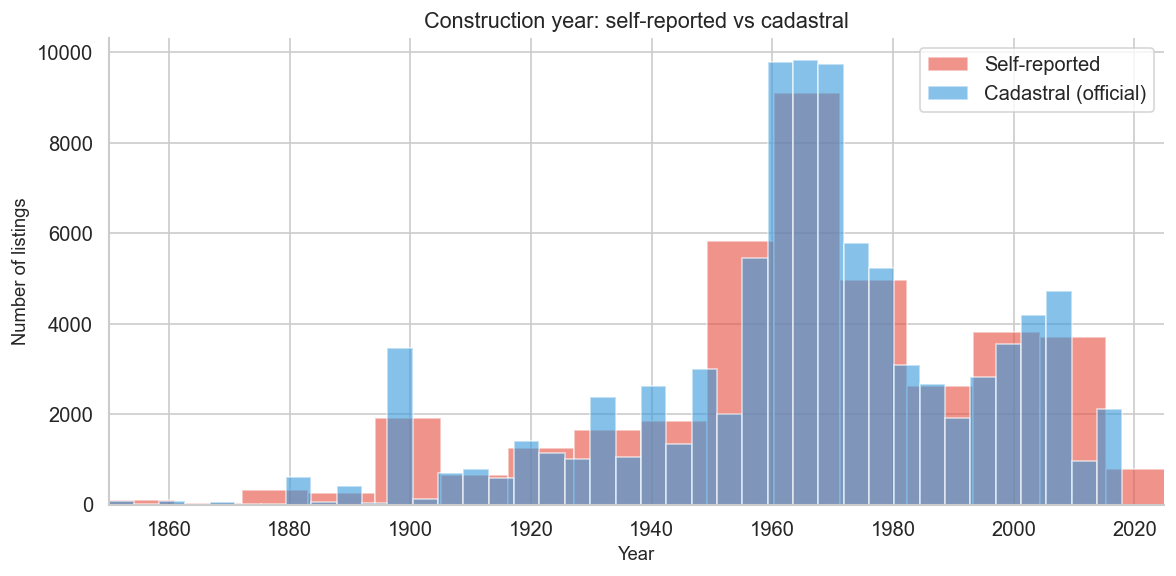

Note: 61 self-reported values below 1850 (erroneous) are excluded from this plot.


In [4]:
# Compare self-reported vs cadastral year distributions
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(cy[cy >= 1850], bins=40, alpha=0.6, color="#e74c3c", label="Self-reported", edgecolor="white")
ax.hist(df["CADCONSTRUCTIONYEAR"][df["CADCONSTRUCTIONYEAR"] >= 1850], bins=40, alpha=0.6,
        color="#3498db", label="Cadastral (official)", edgecolor="white")
ax.set_xlim(1850, 2025)
ax.set_xlabel("Year")
ax.set_ylabel("Number of listings")
ax.set_title("Construction year: self-reported vs cadastral")
ax.legend(frameon=True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

erroneous = cy[cy < 1850]
print(f"Note: {len(erroneous)} self-reported values below 1850 (erroneous) are excluded from this plot.")

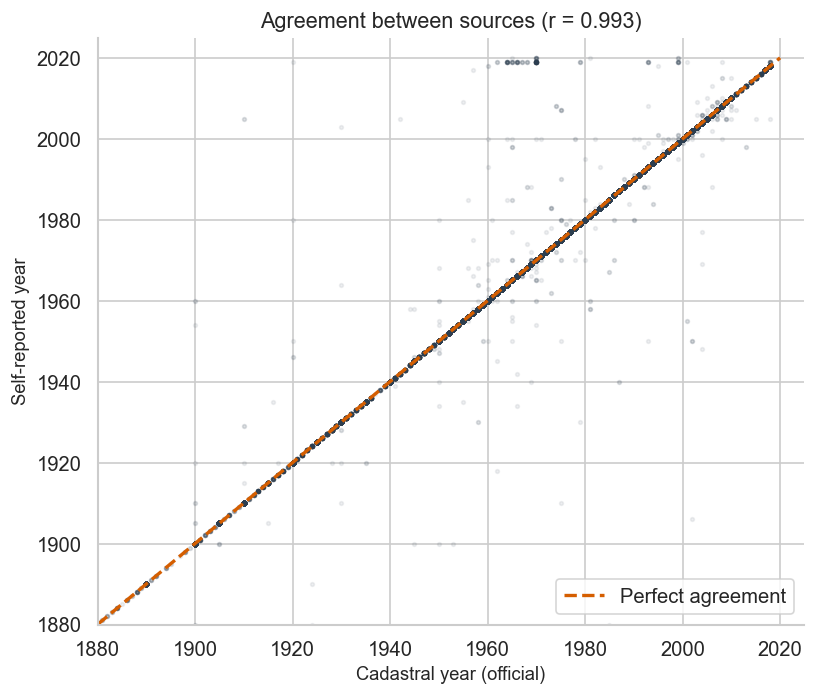

In [5]:
# How well do the two sources agree?
valid = df[df["CONSTRUCTIONYEAR"].between(1880, 2020)]
corr = valid["CONSTRUCTIONYEAR"].corr(valid["CADCONSTRUCTIONYEAR"])

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(valid["CADCONSTRUCTIONYEAR"], valid["CONSTRUCTIONYEAR"],
           alpha=0.08, s=5, color="#2c3e50")
ax.plot([1880, 2020], [1880, 2020], "r--", lw=2, label="Perfect agreement")
ax.set_xlim(1880, 2025)
ax.set_ylim(1880, 2025)
ax.set_xlabel("Cadastral year (official)")
ax.set_ylabel("Self-reported year")
ax.set_title(f"Agreement between sources (r = {corr:.3f})")
ax.legend(frameon=True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

We drop CONSTRUCTIONYEAR. Since the cadastral version is complete and agrees well with the valid self-reported values, there is no reason to keep a column that is 59% empty and contains errors.

In [6]:
df = df.drop(columns=["CONSTRUCTIONYEAR"])
print(f"Dropped CONSTRUCTIONYEAR. Shape: {df.shape}")

Dropped CONSTRUCTIONYEAR. Shape: (94815, 40)


### 1.2 FLATLOCATIONID — 6.7% missing

This column tells us if the flat faces the street (external, 1) or faces an interior patio (internal, 2). About 6,400 listings do not have this info. Let's see if the missing ones behave differently in terms of price.

In [7]:
print(df["FLATLOCATIONID"].value_counts(dropna=False))
print(f"\nMedian PRICE by FLATLOCATIONID:")
print(df.groupby("FLATLOCATIONID", dropna=False)["PRICE"].median())

FLATLOCATIONID
1.0    76324
2.0    12104
NaN     6387
Name: count, dtype: int64

Median PRICE by FLATLOCATIONID:
FLATLOCATIONID
1.0    280000.0
2.0    241000.0
NaN    173000.0
Name: PRICE, dtype: float64


The missing ones have a much lower median price (173k EUR) than both external (280k) and internal (241k) flats. So the missing data is not random — it carries its own signal. We fill it with 0 to keep it as a third category ("unknown") instead of forcing it into one of the other two groups.

In [8]:
df["FLATLOCATIONID"] = df["FLATLOCATIONID"].fillna(0).astype(int)
print(df["FLATLOCATIONID"].value_counts())

FLATLOCATIONID
1    76324
2    12104
0     6387
Name: count, dtype: int64


### 1.3 FLOORCLEAN — 4.1% missing

Floor number of the flat (-1 means basement). About 3,800 listings are missing this. Let's check what kind of properties they are.

In [9]:
print(df["FLOORCLEAN"].value_counts(dropna=False).sort_index())

missing_floor = df["FLOORCLEAN"].isna()
check_cols = ["BUILTTYPEID_1", "BUILTTYPEID_2", "BUILTTYPEID_3", "HASGARDEN", "HASSWIMMINGPOOL"]
comparison = pd.DataFrame({
    "Missing floor": df.loc[missing_floor, check_cols].mean(),
    "All listings": df[check_cols].mean(),
}).round(3)
comparison.index = ["New development", "Second hand, to restore", "Second hand, good condition",
                    "Has garden", "Has swimming pool"]
display(comparison)

print(f"Median price – missing floor: {df.loc[missing_floor, 'PRICE'].median():,.0f} € | "
      f"all listings: {df['PRICE'].median():,.0f} €")

FLOORCLEAN
-1.0       936
 0.0     10112
 1.0     20336
 2.0     17044
 3.0     14754
 4.0     11635
 5.0      6162
 6.0      3733
 7.0      2447
 8.0      1495
 9.0       814
 10.0      450
 11.0     1051
 NaN      3846
Name: count, dtype: int64


,Missing floor,All listings
New development,0.218,0.030
"Second hand, to restore",0.189,0.187
"Second hand, good condition",0.593,0.783
Has garden,0.234,0.185
Has swimming pool,0.262,0.148


Median price – missing floor: 238,000 € | all listings: 262,000 €


These are not random gaps — 22% of them are new developments (vs only 3% in the full dataset), and they tend to have gardens and pools. They are probably houses or new complexes where the floor number just does not apply.

We fill the missing values with the median floor (2) so we don't lose the rows, and we also create a new column FLOOR_MISSING to flag them. That way the model can still pick up the fact that "no floor reported" is a different kind of property.

In [10]:
df["FLOOR_MISSING"] = missing_floor.astype(int)
median_floor = df["FLOORCLEAN"].median()
df["FLOORCLEAN"] = df["FLOORCLEAN"].fillna(median_floor)
print(f"Created FLOOR_MISSING ({df['FLOOR_MISSING'].sum():,} listings) and filled FLOORCLEAN with median = {median_floor:.0f}")

Created FLOOR_MISSING (3,846 listings) and filled FLOORCLEAN with median = 2


### 1.4 CADASTRALQUALITYID — 1 missing

Just one row. We fill it with the mode.

In [11]:
mode_quality = df["CADASTRALQUALITYID"].mode()[0]
df["CADASTRALQUALITYID"] = df["CADASTRALQUALITYID"].fillna(mode_quality)
print(f"Filled 1 missing value with mode = {mode_quality}")

Filled 1 missing value with mode = 4.0


## 2. Erroneous values

### 2.1 Extreme ROOMNUMBER and BATHNUMBER

Some listings report very high numbers of rooms or bathrooms. We need to figure out if these are real (big luxury flats) or typos.

In [12]:
extreme = df[(df["ROOMNUMBER"] > 10) | (df["BATHNUMBER"] > 5)]
print(f"Listings with more than 10 bedrooms or more than 5 bathrooms: {len(extreme)}")
print(extreme[["ROOMNUMBER", "BATHNUMBER", "CONSTRUCTEDAREA", "PRICE"]].describe().round(0))
print(f"\nShare with more than 300 m2: {(extreme['CONSTRUCTEDAREA'] > 300).mean():.0%}")

# Identify impossible listings: less than 10 m2 per bedroom
m2_per_room = df["CONSTRUCTEDAREA"] / df["ROOMNUMBER"].replace(0, np.nan)
impossible = m2_per_room < 10
print(f"\nListings with less than 10 m2 per bedroom: {impossible.sum()}")
display(df.loc[impossible, ["ROOMNUMBER", "BATHNUMBER", "CONSTRUCTEDAREA", "PRICE"]])

Listings with more than 10 bedrooms or more than 5 bathrooms: 288
       ROOMNUMBER  BATHNUMBER  CONSTRUCTEDAREA      PRICE
count       288.0       288.0            288.0      288.0
mean          8.0         7.0            428.0  2342069.0
std           6.0         2.0            200.0  1609089.0
min           4.0         1.0             90.0   109000.0
25%           6.0         6.0            260.0  1197500.0
50%           6.0         6.0            400.0  1947000.0
75%           9.0         7.0            558.0  2912500.0
max          93.0        20.0            982.0  8133000.0

Share with more than 300 m2: 68%

Listings with less than 10 m2 per bedroom: 9


,ROOMNUMBER,BATHNUMBER,CONSTRUCTEDAREA,PRICE
1645,3,0,25,119000.0
7524,3,1,25,54000.0
14134,3,1,28,80000.0
14164,3,1,28,69000.0
17638,93,2,119,450000.0
33410,3,1,28,103000.0
49815,3,1,28,59000.0
75514,6,1,55,188000.0
84059,33,2,90,109000.0


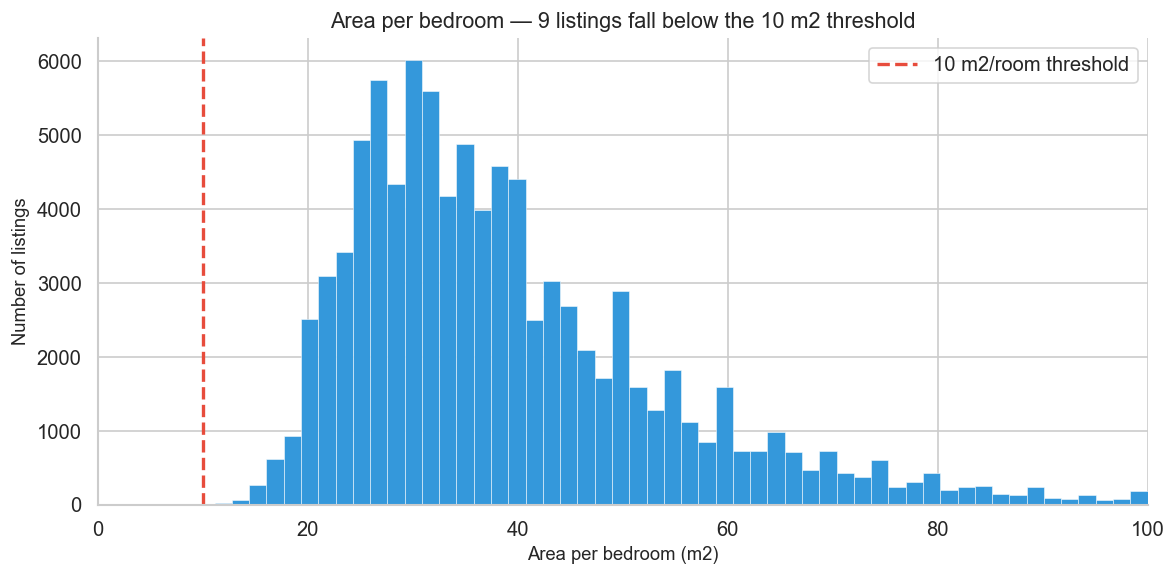

Impossible listings (< 10 m2/room):
       ROOMNUMBER  CONSTRUCTEDAREA
1645            3               25
7524            3               25
14134           3               28
14164           3               28
17638          93              119
33410           3               28
49815           3               28
75514           6               55
84059          33               90


In [13]:
# m2 per bedroom for each listing
m2_per_room_series = df["CONSTRUCTEDAREA"] / df["ROOMNUMBER"].replace(0, np.nan)

fig, ax = plt.subplots(figsize=(10, 5))
valid_ratio = m2_per_room_series.dropna()
ax.hist(valid_ratio[valid_ratio <= 100], bins=60, color="#3498db", edgecolor="white", linewidth=0.3)
ax.axvline(10, color="#e74c3c", linestyle="--", lw=2, label="10 m2/room threshold")
ax.set_xlim(0, 100)
ax.set_xlabel("Area per bedroom (m2)")
ax.set_ylabel("Number of listings")
ax.set_title("Area per bedroom — 9 listings fall below the 10 m2 threshold")
ax.legend(frameon=True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

print("Impossible listings (< 10 m2/room):")
print(df.loc[impossible, ["ROOMNUMBER", "CONSTRUCTEDAREA"]].to_string())

The 288 listings with more than 10 bedrooms or 5 bathrooms are mostly real — they have a median area of 400 m2, median price of 1.9M EUR, and 68% are over 300 m2. These are large luxury properties.

However, 9 listings have less than 10 m2 per bedroom, which is physically impossible (for example, 93 bedrooms in a 119 m2 flat). These are clearly data entry errors, so we remove them. The rest we keep.

In [14]:
n_before = len(df)
df = df[~impossible]
print(f"Removed {n_before - len(df)} listings with an impossible number of bedrooms. Shape: {df.shape}")

Removed 9 listings with an impossible number of bedrooms. Shape: (94806, 41)


### 2.2 PARKINGSPACEPRICE inconsistency

In [15]:
for has_parking in [0, 1]:
    s = df.loc[df["HASPARKINGSPACE"] == has_parking, "PARKINGSPACEPRICE"]
    print(f"HASPARKINGSPACE = {has_parking}: {len(s):,} listings, "
          f"{(s == 1).mean():.1%} with PARKINGSPACEPRICE = 1")
    print(s.value_counts().head(5), "\n")

HASPARKINGSPACE = 0: 73,465 listings, 97.0% with PARKINGSPACEPRICE = 1
PARKINGSPACEPRICE
1        71282
20001      230
30001      209
25001      185
15001      182
Name: count, dtype: int64 

HASPARKINGSPACE = 1: 21,341 listings, 100.0% with PARKINGSPACEPRICE = 1
PARKINGSPACEPRICE
1         21333
50001         1
15001         1
20001         1
220001        1
Name: count, dtype: int64 



Almost every listing has PARKINGSPACEPRICE = 1, whether it has parking or not. It's just a placeholder, not a real price. We drop it — the useful parking info is already in HASPARKINGSPACE and ISPARKINGSPACEINCLUDEDINPRICE.

In [16]:
df = df.drop(columns=["PARKINGSPACEPRICE"])
print(f"Dropped PARKINGSPACEPRICE. Shape: {df.shape}")

Dropped PARKINGSPACEPRICE. Shape: (94806, 40)


### 2.3 Geographic outlier

In [17]:
geo_outlier = df[df["LATITUDE"] < 40]
print(f"Listings with LATITUDE < 40: {len(geo_outlier)}")
print(geo_outlier[["LATITUDE", "LONGITUDE", "PRICE", "CONSTRUCTEDAREA"]])

Listings with LATITUDE < 40: 1
        LATITUDE  LONGITUDE     PRICE  CONSTRUCTEDAREA
84000  36.756391  -2.753303  191000.0              145


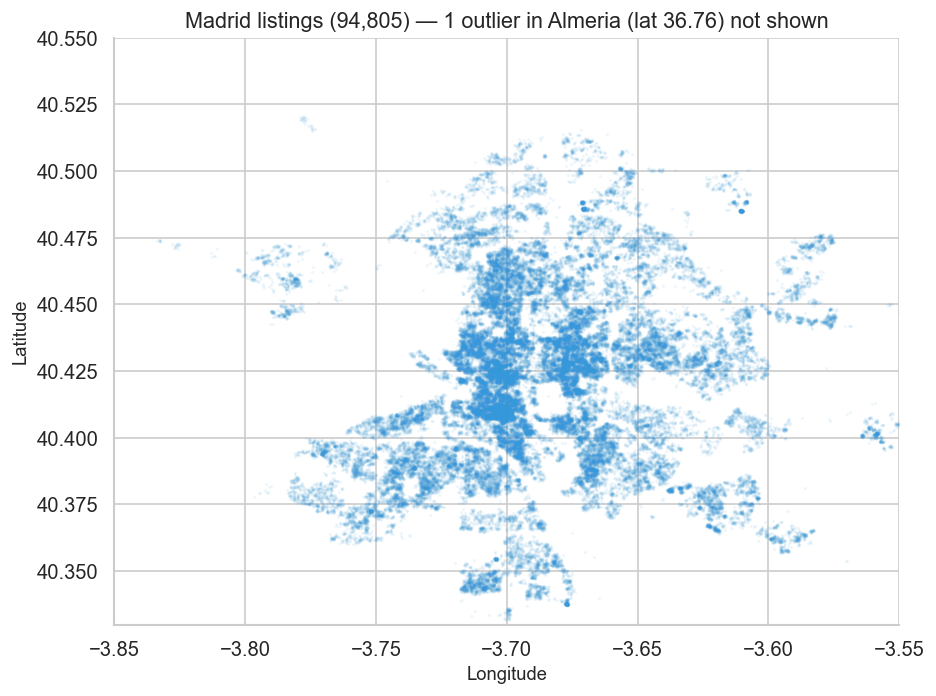

In [18]:
# Show Madrid listings only — the outlier is too far away to fit in the same axes
madrid = df[df["LATITUDE"] >= 40]

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(madrid["LONGITUDE"], madrid["LATITUDE"], alpha=0.05, s=1, color="#3498db")
ax.set_xlim(-3.85, -3.55)
ax.set_ylim(40.33, 40.55)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title(f"Madrid listings ({len(madrid):,}) — 1 outlier in Almeria (lat 36.76) not shown")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

There is one listing with coordinates in Almeria (latitude 36.76), which is hundreds of kilometres from Madrid. It's a geocoding error and we remove it.

In [19]:
df = df[df["LATITUDE"] >= 40]
print(f"Removed geographic outlier. Shape: {df.shape}")

Removed geographic outlier. Shape: (94805, 40)


### 2.4 Duplicate listings

In [20]:
print(f"Total rows: {len(df):,}")
print(f"Unique ASSETIDs: {df['ASSETID'].nunique():,}")
print(f"Repeated rows: {len(df) - df['ASSETID'].nunique():,}")

Total rows: 94,805
Unique ASSETIDs: 75,795
Repeated rows: 19,010


In [21]:
# Investigate duplicates
dups = df[df.duplicated("ASSETID", keep=False)]
g = dups.groupby("ASSETID")

same_flat = ((g["CONSTRUCTEDAREA"].nunique() == 1) & (g["ROOMNUMBER"].nunique() == 1)
             & ((g["LATITUDE"].max() - g["LATITUDE"].min()) < 0.001))
price_changes = g["PRICE"].nunique() > 1
price_spread = g["PRICE"].max() / g["PRICE"].min() - 1

print(f"Repeated properties: {g.ngroups:,}")
print(f"Same area, bedrooms and location: {same_flat.mean():.1%}")
print(f"With different prices: {price_changes.mean():.1%}")
print(f"Median price spread: {price_spread.median():.1%}")

Repeated properties: 13,828
Same area, bedrooms and location: 90.8%
With different prices: 97.9%
Median price spread: 4.4%


About 19,000 rows are repeated ASSETIDs — the same flat listed several times in the same quarter with slightly different prices (median spread of 4.4%). None of them appear across different quarters, so these are just price updates.

If we keep all the copies, the model would treat the same flat as multiple independent observations, which is not correct. We collapse each property into a single row using the median of its prices.

In [22]:
n_before = len(df)
df["PRICE"] = df.groupby("ASSETID")["PRICE"].transform("median")
df = df.drop_duplicates(subset=["ASSETID"], keep="first")
print(f"Kept one row per property with its median price. Removed {n_before - len(df):,} rows. Shape: {df.shape}")

Kept one row per property with its median price. Removed 19,010 rows. Shape: (75795, 40)


### 2.5 Target leakage: UNITPRICE

UNITPRICE is just PRICE divided by CONSTRUCTEDAREA (we showed this in notebook 00). If we left it in, the model would essentially have the answer already — so we drop it.

In [23]:
# Leakage already demonstrated in notebook 00 on the original data:
# UNITPRICE == PRICE / CONSTRUCTEDAREA (max difference 6.4e-12).
df = df.drop(columns=["UNITPRICE"])
print(f"Dropped UNITPRICE (target leakage). Shape: {df.shape}")

Dropped UNITPRICE (target leakage). Shape: (75795, 39)


## Conclusion

We went from 94,815 rows (41 columns) to 75,795 unique properties (39 columns). For missing values: we dropped CONSTRUCTIONYEAR (59% missing) in favour of the complete CADCONSTRUCTIONYEAR, and encoded missing FLATLOCATIONID and FLOORCLEAN as their own categories since the missingness was informative — unknown-location flats are cheaper, and missing-floor listings are mostly new developments.

We also removed 9 listings with impossible room counts, 1 geographic outlier in Almeria, and collapsed ~19,000 duplicates into one row per property using the median price. Finally, we dropped PARKINGSPACEPRICE (useless placeholder) and UNITPRICE (target leakage). Result saved as listings_01.parquet.

In [24]:
import os
os.makedirs("../data/processed", exist_ok=True)
df.to_parquet("../data/processed/listings_01.parquet", index=False)
print(f"Saved: {df.shape[0]} rows × {df.shape[1]} columns")

Saved: 75795 rows × 39 columns
